# 01 - Data Exploration

**RR EDGE - Phase 1: Data Audit & Engineering Foundation**

This notebook loads all six raw datasets and runs the reusable audit and validation modules.

In [1]:
import sys
from pathlib import Path

# Ensure project root is on the path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

## 1. Load All Datasets

In [2]:
from src.data.load_data import load_all, get_dataset_info

datasets = load_all()
for name, df in datasets.items():
    print(f"{name:25s}  {df.shape[0]:>8,} rows × {df.shape[1]:>2} cols")

ball_by_ball                200,999 rows × 33 cols
competitions                    141 rows ×  4 cols
matches                         883 rows × 22 cols
teams                           353 rows ×  3 cols
playing_eleven               28,381 rows ×  9 cols
player_mapping                6,413 rows ×  6 cols


## 2. Dataset Profiles

In [3]:
from src.validation.data_audit import profile_dataframe, print_profile

for name, df in datasets.items():
    profile = profile_dataframe(df, name)
    print_profile(profile)


  ball_by_ball  —  200,999 rows × 33 columns
  Memory: 72.86 MB | Duplicate rows: 0
  Column                                   Type            Nulls       %   Unique
  ---------------------------------------------------------------------------
  match_id                                 int64               0    0.0%      867
  innings                                  int64               0    0.0%        4
  overid                                   int64               0    0.0%       20
  over_ball_num                            int64               0    0.0%       13
  innings_ball_num                         int64               0    0.0%      136
  batting_team_id                          int64               0    0.0%       38
  bowling_team_id                          int64               0    0.0%       38
  striker_id                               int64               0    0.0%      888
  striker_name                             str                 0    0.0%      885
  non_striker_id 

## 3. Relationship Validation

In [4]:
from src.validation.relationship_checks import validate_all_relationships, print_relationship_results

rel_results = validate_all_relationships(datasets)
print_relationship_results(rel_results)


  RELATIONSHIP VALIDATION RESULTS
  ✓ PASS  ball_by_ball.match_id → matches.match_id  (0 issues)
  ✗ FAIL  matches.match_id coverage in ball_by_ball.match_id  (16 issues)
         Sample: [np.int64(31281), np.int64(31284), np.int64(31288), np.int64(32610), np.int64(32612), np.int64(32622), np.int64(36210), np.int64(36564), np.int64(38797), np.int64(40761), np.int64(41502), np.int64(41503), np.int64(42030), np.int64(46008), np.int64(48513), np.int64(50189)]
  ✓ PASS  playing_eleven.match_id → matches.match_id  (0 issues)
  ✗ FAIL  matches.match_id coverage in playing_eleven.match_id  (3 issues)
         Sample: [np.int64(36210), np.int64(41503), np.int64(48513)]
  ✓ PASS  matches.comp_id → competitions.comp_id  (0 issues)
  ✗ FAIL  competitions.comp_id coverage in matches.comp_id  (3 issues)
         Sample: [np.int64(2940), np.int64(3405), np.int64(3473)]
  ✓ PASS  teams.comp_id → competitions.comp_id  (0 issues)
  ✓ PASS  player_mapping.comp_id → competitions.comp_id  (0 issues)
  ✓ 

## 4. Cricket-Specific Quality Checks

In [5]:
from src.cricket.quality_checks import run_all_cricket_checks

cricket_results = run_all_cricket_checks(datasets)
for check_name, result in cricket_results.items():
    print(f"\n--- {check_name} ---")
    for k, v in result.items():
        print(f"  {k}: {v}")


--- innings_coverage ---
  innings_values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  deliveries_per_innings_number: {1: 105727, 2: 95234, 3: 25, 4: 13}
  super_over_match_count: 6

--- over_ball_numbering ---
  over_range: (1, 20)
  ball_num_range: (1, 13)
  innings_ball_max: 136
  balls_per_over_distribution: {1: 93, 2: 88, 3: 103, 4: 129, 5: 146, 6: 25081, 7: 5346, 8: 1085, 9: 222, 10: 42, 11: 13, 13: 2}
  short_over_count: 559
  long_over_count: 6710

--- runs_and_extras ---
  runs_distribution: {0: 79387, 1: 72267, 2: 12547, 3: 656, 4: 23303, 5: 25, 6: 12814}
  extras_type_distribution: {'wide': 7714, 'legbyes': 2748, 'Overstep': 576, 'byes': 529, 'other': 264, 'Penalty': 1}
  wide_runs_always_zero: True
  noball_extras1_always_one: True
  is_four_all_runs_4: True
  is_six_all_runs_6: True
  runs_4_but_not_four_count: 20
  runs_6_but_not_six_count: 3

--- wickets ---
  total_wickets: 10881
  dismissal_type_distribution: {'Caught': 7557, 'Bowled': 1775, 'LBW': 709, 'Ru

## 5. Competition & Format Overview

In [6]:
comp = datasets['competitions']
print(f"Match formats: {comp['match_format'].value_counts().to_dict()}")
print(f"\nSeasons: {sorted(comp['season'].unique())}")

# T20 (franchise) competitions
t20 = comp[comp['match_format'] == 'T20']
print(f"\nT20 (franchise/league) competitions ({len(t20)}):")
for _, row in t20.iterrows():
    print(f"  {row['comp_id']}: {row['comp_name']} ({row['season']})")

Match formats: {'T20I': 134, 'T20': 7}

Seasons: ['2022', '2022/23', '2023', '2023/24', '2024', '2024/25', '2025', '2026']

T20 (franchise/league) competitions (7):
  1358: IPL 2022 (2022)
  1715: IPL 2023 (2023)
  2670: Mens T20 Emerging Teams Asia Cup 2024 (2024)
  2193: IPL 2024 (2024)
  2725: IPL 2025 (2025)
  3289: Asia Cup Rising Stars 2025 (2025)
  3298: IPL 2026 (2026)


## 6. Exploratory Visualizations

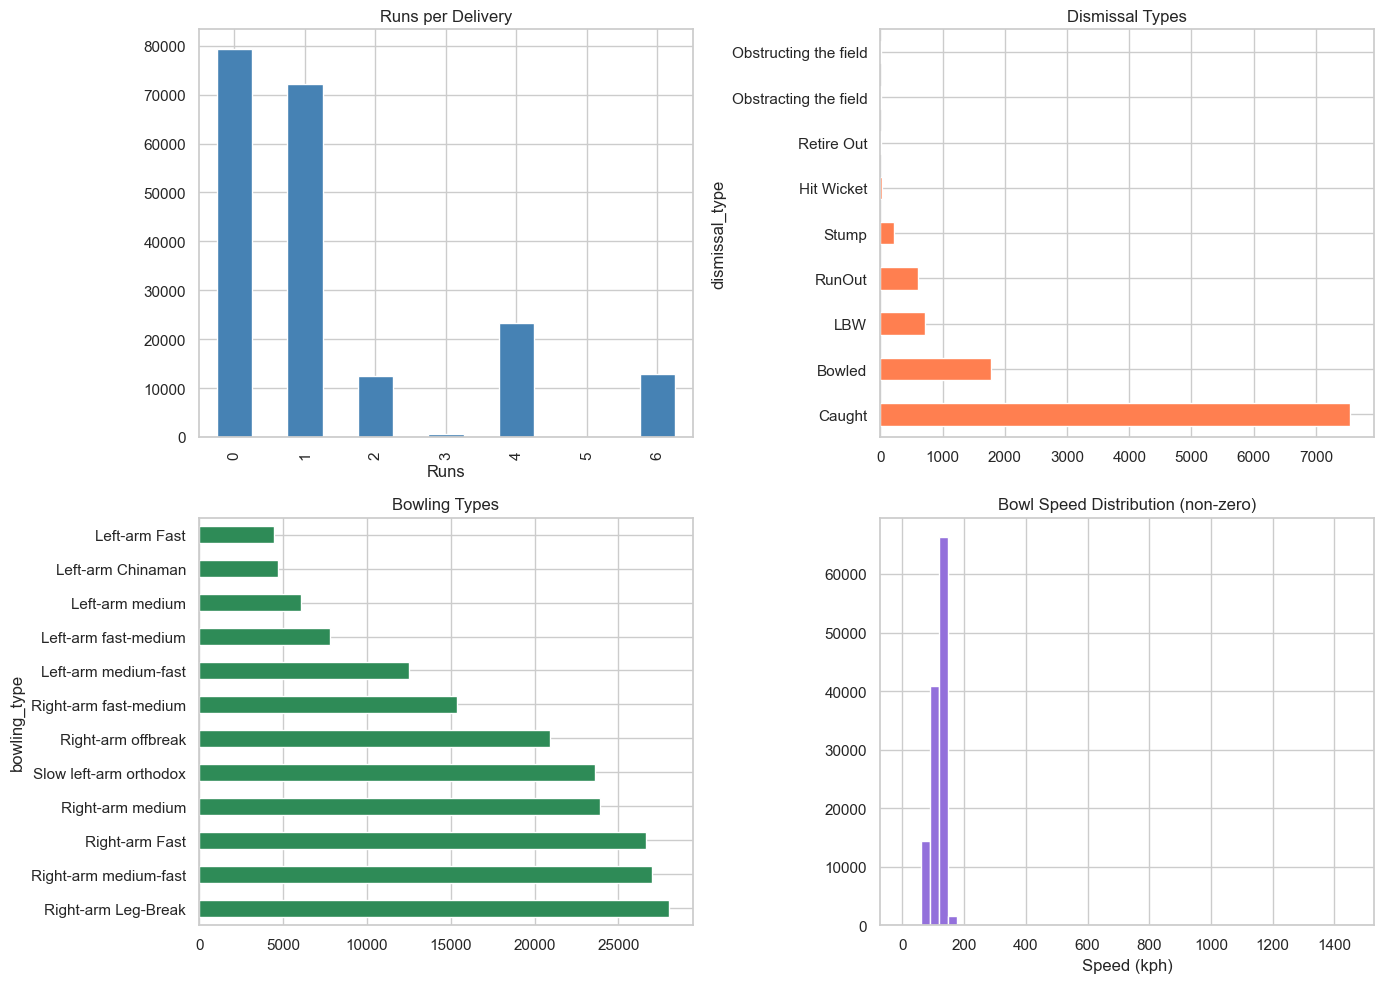

In [7]:
bbb = datasets['ball_by_ball']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Runs distribution
bbb['runs'].value_counts().sort_index().plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Runs per Delivery')
axes[0, 0].set_xlabel('Runs')

# Dismissal types
bbb['dismissal_type'].value_counts().plot(kind='barh', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Dismissal Types')

# Bowling type distribution
bbb['bowling_type'].value_counts().plot(kind='barh', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Bowling Types')

# Bowl speed (non-zero)
nonzero_speed = bbb[bbb['bowl_speed'] > 0]['bowl_speed']
nonzero_speed.hist(bins=50, ax=axes[1, 1], color='mediumpurple', edgecolor='white')
axes[1, 1].set_title('Bowl Speed Distribution (non-zero)')
axes[1, 1].set_xlabel('Speed (kph)')

plt.tight_layout()
plt.savefig('../reports/exploratory_overview.png', dpi=150)
plt.show()

## 7. Pressure Feature Feasibility

In [8]:
from src.cricket.pressure_feasibility import assess_pressure_features

feasibility = assess_pressure_features()

print('=== DIRECTLY AVAILABLE ===')
for k, v in feasibility['directly_available'].items():
    print(f'  {k}: {v}')

print('\n=== DERIVABLE ===')
for k, v in feasibility['derivable'].items():
    print(f'  {k}: {v}')

print('\n=== NOT RELIABLE ===')
for k, v in feasibility['not_reliable'].items():
    print(f'  {k}: {v}')

print('\n=== DERIVATION NOTES ===')
for note in feasibility['derivation_notes']:
    print(f'  • {note}')

=== DIRECTLY AVAILABLE ===
  runs: Batter runs scored off the bat on this delivery (0, 1, 2, 3, 4, 5, 6).
  extras1_runs: Primary extras (penalty or runs from wide, no-ball, bye, leg-bye, penalty).
  extras_2_runs: Secondary extras (overthrows or additional runs on no-balls).
  is_wicket: Authoritative binary flag (True/False) indicating a dismissal occurred.
  dismissal_type: Specific dismissal mechanism (9 categories).
  innings: Innings index (1: first innings, 2: chase, 3/4: super over).
  overid: Current over number (1-indexed: 1 to 20).
  over_ball_num: Delivery sequence within the over (1 to 13, includes extras).
  batting_team_id: Team ID of team currently batting.
  bowling_team_id: Team ID of team currently bowling.
  striker_id: Player ID facing the delivery.
  non_striker_id: Player ID at the bowler's end.
  bowler_id: Player ID delivering the ball.
  batting_type: RHB or LHB.
  bowling_type: 12 granular bowling types.
  pace_or_spin: Binary classification (Pace vs Spin).
 

## 8. Score Reconstruction Verification

Verify that cumulative `runs + extras1_runs + extras_2_runs` matches known match results.

In [9]:
matches = datasets['matches']

# Compute total per innings
innings_totals = bbb.groupby(['match_id', 'innings']).agg(
    total_runs=('runs', 'sum'),
    total_extras1=('extras1_runs', 'sum'),
    total_extras2=('extras_2_runs', 'sum'),
    total_wickets=('is_wicket', 'sum'),
).reset_index()
innings_totals['total_score'] = (
    innings_totals['total_runs']
    + innings_totals['total_extras1']
    + innings_totals['total_extras2']
)

# Show a sample
sample = innings_totals.merge(matches[['match_id', 'result']], on='match_id')
sample[sample['innings'] <= 2].head(20)

,match_id,innings,total_runs,total_extras1,total_extras2,total_wickets,total_score,result
0,13511,1,100,3,0,10,103,West Indies Won by 9 Wickets
1,13511,2,99,5,0,1,104,West Indies Won by 9 Wickets
2,13512,1,163,8,0,8,171,England Won by 1 Run
3,13512,2,158,12,0,8,170,England Won by 1 Run
4,13513,1,211,13,0,5,224,West Indies Won by 20 runs
5,13513,2,192,12,0,9,204,West Indies Won by 20 runs
6,13514,1,182,11,0,6,193,England Won by 34 runs
7,13514,2,150,9,0,5,159,England Won by 34 runs
8,13515,1,168,11,0,4,179,West Indies Won by 17 runs
9,13515,2,150,12,0,10,162,West Indies Won by 17 runs
